# DriverGuard — Ngáp V2 / MobileNetV2 pretrained
Notebook riêng. Giữ nguyên V1 và notebook mắt.
Chọn Runtime → Change runtime type → T4 GPU, sau đó chạy lần lượt.
Dùng lại dataset hiện có và hàm cắt miệng V1. Ảnh webcam không đưa vào train.
Hai giai đoạn: học bộ phân loại với backbone đóng băng, rồi fine-tune một phần backbone.
Không bảo đảm kết quả tốt hơn V1; phải so sánh cả dataset và webcam.


In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'mediapipe'])
from google.colab import drive
drive.mount('/content/drive')
import os, json, hashlib, random, shutil
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import mediapipe as mp
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
DATA_ROOT = Path('/content/drive/MyDrive/DriverGuard/dataset')
OUTPUT_DIR = Path('/content/drive/MyDrive/DriverGuard/models')
IMAGE_SIZE = (96, 96)
BATCH_SIZE = 32
HEAD_EPOCHS = 15
FINE_TUNE_EPOCHS = 10
print('TensorFlow:', tf.__version__, 'MediaPipe:', mp.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0 MediaPipe: 1.1.0
GPU: []


## 1. Đọc dữ liệu và loại ảnh trùng
Chỉ dùng `train/yawn`, `train/no_yawn`, `test/yawn`, `test/no_yawn`.
Nếu đường dẫn khác, sửa **DATA_ROOT** ở ô trên. Không sử dụng hai thư mục ảnh mắt.
Ảnh trùng được kiểm tra bằng nội dung pixel, không chỉ tên file. Kiểm tra này không phát hiện mọi ảnh gần giống nhau hoặc cùng người.


In [ ]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
records = []
broken = []
for split in ('train', 'test'):
    for label_name, label in [('no_yawn', 0), ('yawn', 1)]:
        folder = DATA_ROOT / split / label_name
        if not folder.is_dir():
            raise FileNotFoundError(f'Không tìm thấy: {folder}. Sửa DATA_ROOT, không chạy tiếp.')
        paths = sorted(p for p in folder.rglob('*') if p.suffix.lower() in EXTENSIONS)
        print(split, label_name, ':', len(paths), 'ảnh')
        for path in paths:
            try:
                with Image.open(path) as image:
                    rgb = np.asarray(image.convert('RGB'))
                digest = hashlib.sha256(str(rgb.shape).encode() + rgb.tobytes()).hexdigest()
                records.append({'path': str(path), 'label': label, 'split': split, 'hash': digest})
            except Exception as exc:
                broken.append({'path': str(path), 'error': str(exc)})
labels_by_hash = {}
for record in records:
    labels_by_hash.setdefault(record['hash'], set()).add(record['label'])
conflicts = {h for h, labels in labels_by_hash.items() if len(labels) > 1}
clean = {'train': [], 'test': []}
seen_train = set()
seen_test = set()
removed = {'conflicting_labels': 0, 'train_duplicates': 0, 'test_duplicates_or_overlap': 0}
for split in ('train', 'test'):
    for record in (r for r in records if r['split'] == split):
        digest = record['hash']
        if digest in conflicts:
            removed['conflicting_labels'] += 1
            continue
        if split == 'train':
            if digest in seen_train:
                removed['train_duplicates'] += 1
                continue
            seen_train.add(digest)
        else:
            if digest in seen_train or digest in seen_test:
                removed['test_duplicates_or_overlap'] += 1
                continue
            seen_test.add(digest)
        clean[split].append(record)
print('Ảnh lỗi:', len(broken), '| Loại bỏ:', removed)
print('Sau làm sạch:', {k: len(v) for k, v in clean.items()})
if broken:
    print('Ví dụ lỗi:', broken[:3])


train no_yawn : 616 ảnh
train yawn : 617 ảnh
test no_yawn : 109 ảnh
test yawn : 106 ảnh
Ảnh lỗi: 0 | Loại bỏ: {'conflicting_labels': 0, 'train_duplicates': 0, 'test_duplicates_or_overlap': 0}
Sau làm sạch: {'train': 1233, 'test': 215}


## 2. Cắt miệng bằng MediaPipe
Hàm bên dưới sẽ được lưu riêng để dùng lại khi chạy webcam. Cùng tọa độ, xoay, khoảng đệm, RGB và kích thước ảnh giúp tránh lệch giữa train và chạy thật.
Ảnh không tìm thấy mặt sẽ được bỏ qua và ghi trong báo cáo, không đoán thay bằng MAR.


In [ ]:
CROP_SOURCE = r"""import cv2
import numpy as np
from PIL import Image

MOUTH_POINTS = (61, 146, 91, 181, 84, 17, 314, 405, 321, 375,
                291, 409, 270, 269, 267, 0, 37, 39, 40, 185)

def crop_mouth_rgb(rgb, landmarks, size=(96, 96)):
    # Input must be RGB. Landmarks use normalized MediaPipe coordinates.
    height, width = rgb.shape[:2]
    if len(landmarks) <= max(MOUTH_POINTS):
        raise ValueError('Not enough face landmarks')
    points = np.array([(landmarks[i].x * width, landmarks[i].y * height)
                       for i in MOUTH_POINTS], dtype=np.float32)
    corners = np.array([(landmarks[i].x * width, landmarks[i].y * height)
                        for i in (61, 291)], dtype=np.float32)
    # Sort by image x so the alignment does not rotate the mouth 180 degrees.
    corners = corners[np.argsort(corners[:, 0])]
    delta = corners[1] - corners[0]
    distance = float(np.linalg.norm(delta))
    if distance < 8 or not np.isfinite(points).all():
        raise ValueError('Mouth too small or invalid')
    angle = float(np.degrees(np.arctan2(delta[1], delta[0])))
    matrix = cv2.getRotationMatrix2D(tuple(corners.mean(axis=0).tolist()), angle, 1.0)
    aligned = cv2.warpAffine(rgb, matrix, (width, height),
                             flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    transformed = cv2.transform(points[None, :, :], matrix)[0]
    low, high = transformed.min(axis=0), transformed.max(axis=0)
    center = (low + high) / 2
    side = max(1.6 * distance, float(max(high - low)) + 0.5 * distance)
    x0, y0 = np.floor(center - side / 2).astype(int)
    x1, y1 = np.ceil(center + side / 2).astype(int)
    if x0 < 0 or y0 < 0 or x1 > width or y1 > height:
        raise ValueError('Mouth crop outside image')
    # Reject crops whose corners would sample beyond the rotated original image.
    inverse = cv2.invertAffineTransform(matrix)
    box = np.array([[[x0, y0], [x1 - 1, y0], [x1 - 1, y1 - 1], [x0, y1 - 1]]], dtype=np.float32)
    original_box = cv2.transform(box, inverse)[0]
    if (original_box[:, 0] < 0).any() or (original_box[:, 0] >= width).any() or \
       (original_box[:, 1] < 0).any() or (original_box[:, 1] >= height).any():
        raise ValueError('Aligned crop outside original image')
    crop = aligned[y0:y1, x0:x1]
    if crop.size == 0:
        raise ValueError('Empty mouth crop')
    return np.asarray(Image.fromarray(crop).resize(size, Image.Resampling.BICUBIC), dtype=np.uint8)
"""
exec(CROP_SOURCE)
import urllib.request
TASK_PATH = Path('/content/face_landmarker.task')
if not TASK_PATH.exists():
    urllib.request.urlretrieve(
        'https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task',
        TASK_PATH)
options = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path=str(TASK_PATH)),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_faces=1, min_face_detection_confidence=0.5,
    min_face_presence_confidence=0.5)
arrays = {}
skipped = []
accepted = {'train': [], 'test': []}
with mp.tasks.vision.FaceLandmarker.create_from_options(options) as detector:
    for split in ('train', 'test'):
        images, labels = [], []
        for index, record in enumerate(clean[split], 1):
            try:
                with Image.open(record['path']) as image:
                    rgb = np.asarray(image.convert('RGB'))
                scale = min(1.0, 640 / max(rgb.shape[:2]))
                detection_rgb = cv2.resize(rgb, None, fx=scale, fy=scale) if scale < 1 else rgb
                result = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB,
                                                  data=np.ascontiguousarray(detection_rgb)))
                if not result.face_landmarks:
                    raise ValueError('No face detected')
                images.append(crop_mouth_rgb(rgb, result.face_landmarks[0], IMAGE_SIZE))
                labels.append(record['label'])
                accepted[split].append(record)
            except Exception as exc:
                skipped.append({'path': record['path'], 'label': record['label'], 'error': str(exc)})
            if index % 100 == 0 or index == len(clean[split]):
                print(f'{split}: {index}/{len(clean[split])} — giữ {len(images)} ảnh')
        arrays[split] = (np.asarray(images, dtype=np.uint8), np.asarray(labels, dtype=np.int32))
print('Bỏ qua khi cắt miệng:', len(skipped))
for split, (_, labels) in arrays.items():
    print(split, 'no_yawn:', int((labels == 0).sum()), 'yawn:', int((labels == 1).sum()))
    if min(int((labels == 0).sum()), int((labels == 1).sum())) < 20:
        raise ValueError('Quá ít ảnh hợp lệ của một lớp. Kiểm tra dữ liệu/cắt miệng trước khi train.')


train: 100/1233 — giữ 99 ảnh
train: 200/1233 — giữ 198 ảnh
train: 300/1233 — giữ 298 ảnh
train: 400/1233 — giữ 397 ảnh
train: 500/1233 — giữ 497 ảnh
train: 600/1233 — giữ 596 ảnh
train: 700/1233 — giữ 696 ảnh
train: 800/1233 — giữ 795 ảnh
train: 900/1233 — giữ 891 ảnh
train: 1000/1233 — giữ 989 ảnh
train: 1100/1233 — giữ 1089 ảnh
train: 1200/1233 — giữ 1186 ảnh
train: 1233/1233 — giữ 1218 ảnh
test: 100/215 — giữ 99 ảnh
test: 200/215 — giữ 196 ảnh
test: 215/215 — giữ 211 ảnh
Bỏ qua khi cắt miệng: 19
train no_yawn: 612 yawn: 606
test no_yawn: 108 yawn: 103


## 3. Xem vùng miệng trước khi train
Kiểm tra có đủ môi và phần miệng đang mở. Nếu vùng cắt sai, dừng ở đây; không train để sửa lỗi cắt ảnh.


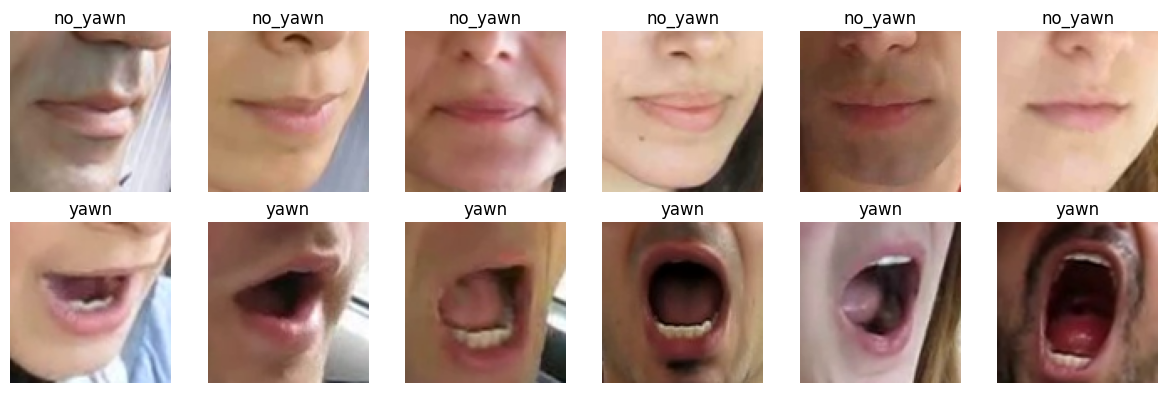

In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
x_all, y_all = arrays['train']
for label in (0, 1):
    indices = np.flatnonzero(y_all == label)
    choices = np.random.default_rng(SEED).choice(indices, size=6, replace=len(indices) < 6)
    for column, index in enumerate(choices):
        axes[label, column].imshow(x_all[index])
        axes[label, column].set_title('yawn' if label else 'no_yawn')
        axes[label, column].axis('off')
plt.tight_layout()
plt.show()


## 4. MobileNetV2 pretrained
Input vẫn là RGB 96×96, giá trị 0–255. Model tự chuyển về -1…1 theo chuẩn MobileNetV2.
Backbone được train trước trên ImageNet, chưa được train sẵn để nhận ngáp.
Validation lấy 20% train; chưa có mã người nên đây vẫn là chia theo ảnh, không chứng minh nhận người mới.


In [ ]:
train_indices, val_indices = train_test_split(
    np.arange(len(y_all)), test_size=0.2, stratify=y_all, random_state=SEED)
x_train, y_train = x_all[train_indices], y_all[train_indices]
x_val, y_val = x_all[val_indices], y_all[val_indices]
x_test, y_test = arrays['test']
tf.keras.backend.clear_session()
base = tf.keras.applications.MobileNetV2(input_shape=(96, 96, 3),
                                        include_top=False, weights='imagenet')
base.trainable = False
inputs = tf.keras.Input(shape=(96, 96, 3))
x = tf.keras.layers.RandomFlip('horizontal', seed=SEED)(inputs)
# Brightness augmentation applies to the original 0–255 range, before normalization.
x = tf.keras.layers.RandomBrightness(0.12, value_range=(0, 255), seed=SEED)(x)
x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)
# Keep batch-normalization statistics fixed, including during fine-tuning.
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)
model = tf.keras.Model(inputs, outputs, name='driverguard_yawn_mobilenet_v2')
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
              loss='binary_crossentropy', metrics=['accuracy'])
model.summary()
print('Train:', len(y_train), 'Validation:', len(y_val), 'Test:', len(y_test))


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "driverguard_yawn_mobilenet_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 96, 96, 3)      │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Train: 974 Validation: 244 Test: 211


## 5. Train hai giai đoạn
Early stopping chọn trọng số theo validation loss. Nếu fine-tune làm validation kém hơn, tự giữ trọng số giai đoạn đầu. Không chọn model bằng test.


GIAI ĐOẠN 1 — train bộ phân loại
Epoch 1/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 17s 407ms/step - accuracy: 0.8357 - loss: 0.3743 - val_accuracy: 0.9262 - val_loss: 0.2246 - learning_rate: 0.0010
Epoch 2/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 372ms/step - accuracy: 0.9343 - loss: 0.1860 - val_accuracy: 0.9467 - val_loss: 0.1528 - learning_rate: 0.0010
Epoch 3/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 360ms/step - accuracy: 0.9600 - loss: 0.1358 - val_accuracy: 0.9631 - val_loss: 0.1219 - learning_rate: 0.0010
Epoch 4/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 343ms/step - accuracy: 0.9733 - loss: 0.1007 - val_accuracy: 0.9754 - val_loss: 0.1032 - learning_rate: 0.0010
Epoch 5/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 318ms/step - accuracy: 0.9723 - loss: 0.0975 - val_accuracy: 0.9795 - val_loss: 0.0895 - learning_rate: 0.0010
Epoch 6/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 10s 314ms/step - accuracy: 0.9805 - loss: 0.0748 - val_accuracy: 0.9877 - val_loss: 0.0790 - learning_rate: 0.0010
Epoch 7/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 9s 266ms/st

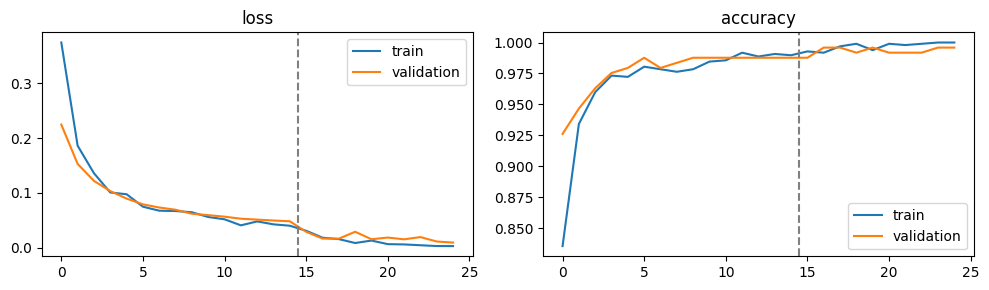

In [ ]:
def training_callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5, min_lr=1e-7)]
counts = np.bincount(y_train, minlength=2)
class_weight = {i: len(y_train) / (2 * int(counts[i])) for i in (0, 1)}
print('GIAI ĐOẠN 1 — train bộ phân loại')
head_history = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                        batch_size=BATCH_SIZE, epochs=HEAD_EPOCHS,
                        callbacks=training_callbacks(), class_weight=class_weight, verbose=1)
head_loss = float(model.evaluate(x_val, y_val, verbose=0)[0])
head_weights = model.get_weights()
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(0.00001),
              loss='binary_crossentropy', metrics=['accuracy'])
print('GIAI ĐOẠN 2 — fine-tune với learning rate nhỏ')
fine_history = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                        batch_size=BATCH_SIZE, epochs=FINE_TUNE_EPOCHS,
                        callbacks=training_callbacks(), class_weight=class_weight, verbose=1)
fine_loss = float(model.evaluate(x_val, y_val, verbose=0)[0])
selected_stage = 'fine_tune'
if fine_loss >= head_loss:
    model.set_weights(head_weights)
    selected_stage = 'head_only'
print('Model được giữ:', selected_stage, '| validation loss:', min(head_loss, fine_loss))
history_data = {'head': head_history.history, 'fine_tune': fine_history.history}
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for axis, metric in zip(axes, ['loss', 'accuracy']):
    axis.plot(head_history.history[metric] + fine_history.history[metric], label='train')
    axis.plot(head_history.history['val_' + metric] + fine_history.history['val_' + metric], label='validation')
    axis.axvline(len(head_history.history[metric]) - 0.5, color='gray', linestyle='--')
    axis.set_title(metric)
    axis.legend()
plt.tight_layout()
plt.show()


## 6. Đánh giá test
Ngưỡng score 0.5 chuyển đầu ra sigmoid thành nhãn; đây không phải ngưỡng MAR. Không chỉnh model dựa vào test rồi gọi test đó là đánh giá độc lập.
Độ chính xác trên bộ ảnh này không bảo đảm đúng với webcam, góc nghiêng, ánh sáng tối hay nói chuyện.


Test accuracy: 97.63% | loss: 0.0898
              precision    recall  f1-score   support

     no_yawn       0.97      0.98      0.98       108
        yawn       0.98      0.97      0.98       103

    accuracy                           0.98       211
   macro avg       0.98      0.98      0.98       211
weighted avg       0.98      0.98      0.98       211



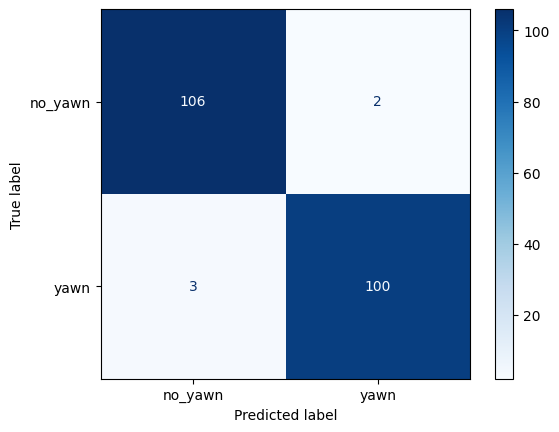

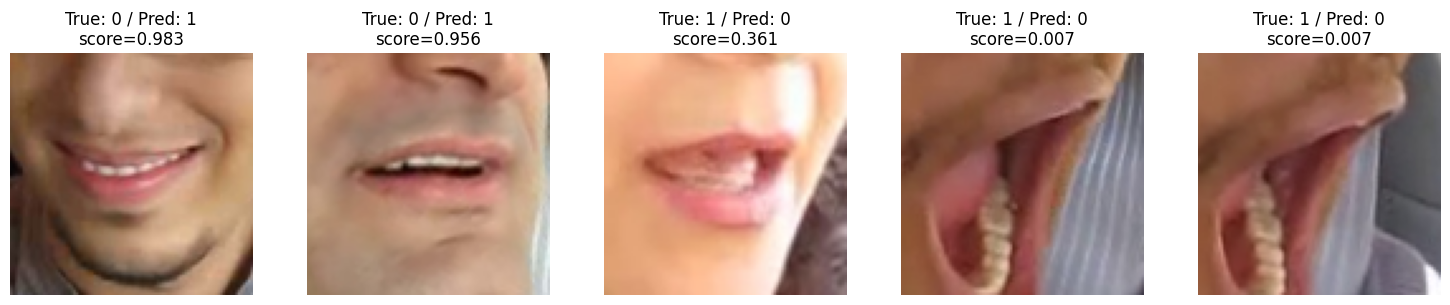

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
scores = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0).ravel()
predictions = (scores >= 0.5).astype(np.int32)
report = classification_report(y_test, predictions, labels=[0, 1],
                               target_names=['no_yawn', 'yawn'], output_dict=True, zero_division=0)
print(f'Test accuracy: {test_accuracy:.2%} | loss: {test_loss:.4f}')
print(classification_report(y_test, predictions, labels=[0, 1],
                            target_names=['no_yawn', 'yawn'], zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, predictions, labels=[0, 1]),
                       display_labels=['no_yawn', 'yawn']).plot(cmap='Blues')
plt.show()
wrong = np.flatnonzero(predictions != y_test)[:8]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3 * len(wrong), 3), squeeze=False)
    for axis, index in zip(axes[0], wrong):
        axis.imshow(x_test[index])
        axis.set_title(f'True: {y_test[index]} / Pred: {predictions[index]}\nscore={scores[index]:.3f}')
        axis.axis('off')
    plt.tight_layout()
    plt.show()


## 7. Lưu model, hàm cắt và báo cáo
Mỗi lần chạy tạo một thư mục mới, không ghi đè model mắt hay model ngáp trước đó.
Sau khi train xong, gửi bảng đánh giá ở bước 6. Bước tiếp theo là tích hợp webcam bằng đúng hàm cắt này và kiểm tra ngáp/nói/cười thực tế.


In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
run_dir = OUTPUT_DIR / ('yawn_mobilenet_v2_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
run_dir.mkdir()
model_path = run_dir / 'yawn_model_v2.keras'
model.save(model_path)
(run_dir / 'mouth_crop.py').write_text(CROP_SOURCE, encoding='utf-8')
metadata = {
    'model_file': model_path.name, 'input_shape': [96, 96, 3],
    'input_color': 'RGB', 'input_range': [0, 255],
    'normalization': 'Rescaling(1/127.5, offset=-1) inside model; pass raw RGB 0–255',
    'labels': {'0': 'no_yawn', '1': 'yawn'}, 'decision_threshold': 0.5,
    'architecture': 'MobileNetV2 ImageNet transfer learning', 'selected_stage': selected_stage, 'seed': SEED, 'tensorflow_version': tf.__version__, 'mediapipe_version': mp.__version__,
    'crop_file': 'mouth_crop.py', 'face_landmarker_file': 'face_landmarker.task',
    'crop_sha256': hashlib.sha256(CROP_SOURCE.encode()).hexdigest(),
    'test_accuracy': float(test_accuracy), 'test_loss': float(test_loss),
    'train_count': len(y_train), 'validation_count': len(y_val), 'test_count': len(y_test),
    'limitations': ['Image-level split, not confirmed subject-independent',
                    'Exact pixel duplicates removed, near-duplicates may remain',
                    'Static mouth images do not establish drowsiness or reliably separate speech'],
}
(run_dir / 'metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')
audit = {'removed': removed, 'broken': broken, 'skipped_crops': skipped,
         'train': [accepted['train'][i] for i in train_indices],
         'validation': [accepted['train'][i] for i in val_indices], 'test': accepted['test'],
         'classification_report': report, 'history': history_data, 'selected_stage': selected_stage}
(run_dir / 'training_report.json').write_text(json.dumps(audit, indent=2, ensure_ascii=False), encoding='utf-8')
shutil.copy2(TASK_PATH, run_dir / 'face_landmarker.task')
loaded = tf.keras.models.load_model(model_path)
np.testing.assert_allclose(model(x_test[:2], training=False).numpy(),
                           loaded(x_test[:2], training=False).numpy(), rtol=1e-5, atol=1e-6)
print('Đã lưu và kiểm tra nạp lại model:', model_path)
print('Hàm cắt / cấu hình / báo cáo:', run_dir)


Đã lưu và kiểm tra nạp lại model: /content/drive/MyDrive/DriverGuard/models/yawn_mobilenet_v2_20261011_095913_872603/yawn_model_v2.keras
Hàm cắt / cấu hình / báo cáo: /content/drive/MyDrive/DriverGuard/models/yawn_mobilenet_v2_20261011_095913_872603
